In [1]:
#imports
import nibabel as nib
#import nilearn
import numpy as np
import os
import cv2
from matplotlib import pyplot as plt

from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()

In [2]:
#from tqdm import tqdm
from skimage.io import imread, imshow
from skimage.transform import resize

In [3]:
import tensorflow as tf

import keras.backend as K
from keras.models import Model, load_model
from keras.layers import Input, BatchNormalization, Activation, Dense, Dropout
from keras.layers.core import Lambda, RepeatVector, Reshape
from keras.layers.convolutional import Conv2D, Conv2DTranspose
from keras.layers.pooling import MaxPooling2D, GlobalMaxPool2D
from tensorflow.keras.layers import concatenate
#from keras.layers.merge import concatenate, add
from keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from keras.callbacks import CSVLogger
#from keras.preprocessing.image import ImageDataGenerator, array_to_img, img_to_array, load_img
from tensorflow.keras.models import *
from tensorflow.keras.layers import *
from tensorflow.keras.optimizers import *
from tensorflow.keras.callbacks import ModelCheckpoint, ReduceLROnPlateau, EarlyStopping, TensorBoard
from tensorflow.keras.layers.experimental import preprocessing

from tensorflow.keras.losses import binary_crossentropy

#from focal_loss import BinaryFocalLoss

2025-06-24 10:21:15.440733: I tensorflow/core/platform/cpu_feature_guard.cc:193] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  AVX2 FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.
2025-06-24 10:21:15.576271: E tensorflow/stream_executor/cuda/cuda_blas.cc:2981] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2025-06-24 10:21:16.103743: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libnvinfer.so.7'; dlerror: libnvinfer.so.7: cannot open shared object file: No such file or directory; LD_LIBRARY_PATH: /home/islesenv/lib/python3.9/site-packages/cv2/../../lib64:/usr/local/cuda/extras/CUPTI/lib64:/usr/local/cuda/compat/lib:/usr/local/nvidia/lib:/usr/local/nvidia/lib64
2025-06-24 10:21:16.103838: W tensorflow/stre

In [4]:
print("Num GPUs Available: ", len(tf.config.list_physical_devices('GPU')))

physical_devices = tf.config.list_physical_devices("GPU")
tf.config.experimental.set_memory_growth(physical_devices[0], True)

Num GPUs Available:  1


2025-06-24 10:21:19.898374: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:980] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2025-06-24 10:21:19.932186: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:980] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2025-06-24 10:21:19.933644: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:980] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero


In [5]:
TRAIN_DATASET_PATH = 'Dataset_ISLES22/ISLES22/rawdata'
train_directories = [f.path for f in os.scandir(TRAIN_DATASET_PATH) if f.is_dir()]

train_ids = []
for i in range(len(train_directories)):
    train_ids.append(train_directories[i][32:50])
train_ids.sort()
print(len(train_ids))

250


In [6]:
TRAINMask_DATASET_PATH = 'Dataset_ISLES22/ISLES22/derivatives'
mask_directories = [f.path for f in os.scandir(TRAINMask_DATASET_PATH) if f.is_dir()]
mask_ids = []
for i in range(len(mask_directories)):
    mask_ids.append(mask_directories[i][36:54])
mask_ids.sort()
print(len(mask_ids))

250


In [7]:
from sklearn.model_selection import train_test_split
train_val_ids, test_ids,train_val_mask, test_mask = train_test_split(train_ids,mask_ids,test_size=0.20,random_state=42) 
train_ids,  val_ids, train_mask , val_mask = train_test_split(train_val_ids,train_val_mask,test_size=0.20,random_state=42)
len(train_ids)

160

In [8]:
print('trainingId:',len(train_ids))
print('val_Id:',len(val_ids))
print('Test_Id:',len(test_ids))

trainingId: 160
val_Id: 40
Test_Id: 50


In [9]:
train_ids

['sub-strokecase0062',
 'sub-strokecase0093',
 'sub-strokecase0214',
 'sub-strokecase0238',
 'sub-strokecase0134',
 'sub-strokecase0107',
 'sub-strokecase0087',
 'sub-strokecase0235',
 'sub-strokecase0132',
 'sub-strokecase0156',
 'sub-strokecase0191',
 'sub-strokecase0130',
 'sub-strokecase0067',
 'sub-strokecase0050',
 'sub-strokecase0146',
 'sub-strokecase0091',
 'sub-strokecase0014',
 'sub-strokecase0071',
 'sub-strokecase0192',
 'sub-strokecase0227',
 'sub-strokecase0161',
 'sub-strokecase0206',
 'sub-strokecase0057',
 'sub-strokecase0118',
 'sub-strokecase0066',
 'sub-strokecase0004',
 'sub-strokecase0036',
 'sub-strokecase0211',
 'sub-strokecase0145',
 'sub-strokecase0224',
 'sub-strokecase0096',
 'sub-strokecase0164',
 'sub-strokecase0170',
 'sub-strokecase0013',
 'sub-strokecase0183',
 'sub-strokecase0095',
 'sub-strokecase0030',
 'sub-strokecase0009',
 'sub-strokecase0065',
 'sub-strokecase0210',
 'sub-strokecase0239',
 'sub-strokecase0099',
 'sub-strokecase0023',
 'sub-strok

In [10]:
len(test_ids)
#tc=test_ids[0:2]
#tc
test_ids

['sub-strokecase0143',
 'sub-strokecase0007',
 'sub-strokecase0098',
 'sub-strokecase0061',
 'sub-strokecase0113',
 'sub-strokecase0182',
 'sub-strokecase0198',
 'sub-strokecase0185',
 'sub-strokecase0010',
 'sub-strokecase0105',
 'sub-strokecase0201',
 'sub-strokecase0217',
 'sub-strokecase0237',
 'sub-strokecase0241',
 'sub-strokecase0068',
 'sub-strokecase0225',
 'sub-strokecase0195',
 'sub-strokecase0016',
 'sub-strokecase0178',
 'sub-strokecase0025',
 'sub-strokecase0248',
 'sub-strokecase0020',
 'sub-strokecase0115',
 'sub-strokecase0069',
 'sub-strokecase0177',
 'sub-strokecase0046',
 'sub-strokecase0056',
 'sub-strokecase0011',
 'sub-strokecase0031',
 'sub-strokecase0121',
 'sub-strokecase0202',
 'sub-strokecase0034',
 'sub-strokecase0142',
 'sub-strokecase0220',
 'sub-strokecase0026',
 'sub-strokecase0112',
 'sub-strokecase0019',
 'sub-strokecase0197',
 'sub-strokecase0181',
 'sub-strokecase0160',
 'sub-strokecase0119',
 'sub-strokecase0097',
 'sub-strokecase0109',
 'sub-strok

In [11]:
# defining the performance metrics
def dice_coeff(y_true,y_pred):
    # Perform the conditional operation using TensorFlow
    # Set values less than 2.2 to 0
    y_pred = tf.where(y_pred < 0.2, tf.zeros_like(y_pred), y_pred)
    
    # Apply threshold to create binary predictions
    #y_pred = tf.where(y_pred >= 0.5, 1.0, 0.0)
    # Convert to float32
    #y_pred = tf.cast(y_pred, tf.float32)
    
    # If y_pred < 0.5, return 0.0; otherwise, return 1.0
    #y_pred = tf.where(y_pred < 0.5, tf.zeros_like(y_pred), tf.ones_like(y_pred))
    y_true_new = K.flatten(y_true)
    y_pred_new = K.flatten(y_pred)
    denominator = K.sum(y_true_new) + K.sum(y_pred_new)
    if denominator == 0.0:
        return 1.0
    numerator = K.sum(y_true_new * y_pred_new)
    return (2.0*numerator)/(denominator)

def dice_coeff_loss(y_true,y_pred):
    return 1.0- dice_coeff(y_true,y_pred)

def precision(y_true, y_pred):
        true_positives = K.sum(K.round(K.clip(y_true * y_pred, 0, 1)))
        predicted_positives = K.sum(K.round(K.clip(y_pred, 0, 1)))
        precision = true_positives / (predicted_positives + K.epsilon())
        return precision

def dsc(y_true, y_pred):
    neg_y_true = 1 - y_true
    neg_y_pred = 1 - y_pred
    tp = K.sum(y_true * y_pred)
    fn = K.sum(y_true * neg_y_pred)
    fp = K.sum(neg_y_true * y_pred)
    dsc = (2*tp+1) / ((2*tp) + fn + fp + 1)
    return dsc    

def iou(y_true,y_pred):
    y_pred = tf.where(y_pred < 0.2, tf.zeros_like(y_pred), y_pred)
    # Apply threshold to create binary predictions
    #y_pred = tf.where(y_pred >= 0.5, 1.0, 0.0)
    # Convert to float32
    #y_pred = tf.cast(y_pred, tf.float32)
    y_true = K.flatten(y_true)
    y_pred = K.flatten(y_pred)
    intersec = K.sum(y_true * y_pred)
    union = K.sum(y_true + y_pred)
    if union == 0.0:
        return 1.0
    iou = (intersec) / (union- intersec)
    return iou

def dice_score(y_true, y_pred):
    intersection = tf.reduce_sum(y_true * y_pred)
    union = tf.reduce_sum(y_true) + tf.reduce_sum(y_pred)
    dice = (2.0 * intersection + 0.1) / (union + 0.1)
    return dice

def dice_loss(y_true, y_pred):
    return 1.0 -dice_score(y_true, y_pred)

def bce_dice_loss(y_true, y_pred):
    loss = tf.keras.losses.binary_crossentropy(y_true, y_pred) + dice_coeff_loss(y_true, y_pred)
    return loss

def ce_dice_loss(y_true, y_pred):
    loss = tf.keras.losses.categorical_crossentropy(y_true, y_pred) + dice_coeff_loss(y_true, y_pred)
    return loss

In [12]:
def precision_score_(y_true, y_pred):
    #y_pred = tf.where(y_pred < 0.2, tf.zeros_like(y_pred), y_pred)
    # Apply threshold to create binary predictions
    #y_pred = tf.where(y_pred >= 0.5, 1.0, 0.0)
    # Convert to float32
    #y_pred = tf.cast(y_pred, tf.float32)
    y_true_new = K.flatten(y_true)
    y_pred_new = K.flatten(y_pred)
    intersect = K.sum(y_pred_new*y_true_new)
    total_pixel_pred = K.sum(y_pred_new)
    #precision = intersect/total_pixel_pred
    return intersect/total_pixel_pred

def recall_score_(y_true, y_pred):
    y_true_new = K.flatten(y_true)
    y_pred_new = K.flatten(y_pred)
    intersect = K.sum(y_pred_new*y_true_new)
    total_pixel_truth = K.sum(y_true_new)
    #recall = np.mean(intersect/total_pixel_truth)
    return intersect/total_pixel_truth

In [13]:
import tensorflow as tf
from tensorflow.keras.layers import Conv2D
from tensorflow.keras.layers import GlobalAveragePooling2D, GlobalMaxPooling2D, Reshape, Dense, Input, GlobalMaxPooling1D
from tensorflow.keras.layers import Activation, Concatenate, Conv2D, Multiply, Add

from tensorflow.keras.models import Model
from tensorflow.keras import backend as K

#spatial self-Attention HW
def self_attention(inp):
    shp = inp.shape
    q = Conv2D(shp[3], 1, padding='same')(inp)
    q = Activation('relu')(q)
    
    k = Conv2D(shp[3], 1, padding='same')(inp)
    k = Activation('relu')(k)
    
    v = Conv2D(shp[3], 1, padding='same')(inp)
    v = Activation('relu')(v)
    
    qkv = Conv2D(shp[3], 1, padding='same')(inp)
    qkv = Activation('relu')(qkv)    
    
    q = Reshape((shp[1] * shp[2], shp[3]))(q)
    k = Reshape((shp[1] * shp[2], shp[3]))(k)
    k = K.permute_dimensions(k, (0, 2, 1))
    print('k',k.shape)
    v = Reshape((shp[1] * shp[2], shp[3]))(v)
    inter = K.batch_dot(q, k)
    print('qk',inter.shape)
    inter = Activation('softmax')(inter)
    out = K.batch_dot(inter, v)
    print('qkv',out.shape)
    out = Reshape((shp[1], shp[2], shp[3]))(out)
    out = Conv2D(shp[3], 1, padding='same')(out)
    out = Activation('relu')(out)
    print('SAOut=',out.shape)
    
    out = Multiply()([inp,out])
    print('skipout=',out.shape)
    
    return out

#Channel-height self-Attention
def spatial_attention_module(x):
    ## Average Pooling
    x1 = tf.reduce_mean(x, axis=-1, keepdims=True)
    print('x1',x1.shape)

    ## Max Pooling
    x2 = tf.reduce_max(x, axis=-1, keepdims=True)
    print('x2',x2.shape)

    ## Concatenate both the features
    feats = Concatenate()([x1, x2])
    print('feats',feats.shape)
    ## Conv layer
    feats = Conv2D(1, kernel_size=7, padding="same", activation="sigmoid")(feats)
    #feats = Multiply()([x, feats])
    print('out',feats.shape)

    return feats

def CH_self_attention_block(x,filters):
    # Compute query, key, value
    x_shape = tf.shape(x)
    query = Conv2D(filters, kernel_size=1)(x)
    key = Conv2D(filters, kernel_size=1)(x)
    value = Conv2D(filters, kernel_size=1)(x)
    
    query = tf.transpose(query, perm=[0, 3, 1, 2])
    print('tran1',query.shape)
    query = spatial_attention_module(query)
    print('query',query.shape)
    
    # Reshape and compute attention scores
    query_shape = tf.shape(query)
    query = tf.reshape(query, (query_shape[0],query_shape[-1],query_shape[1] * query_shape[2]))  # (batch, height*width, filters//8)
    print('q=',query.shape)
    
    key = GlobalAveragePooling2D(keepdims=True)(key)
    print('gq',key.shape)
    key_shape = tf.shape(key)
    key = tf.reshape(key, (key_shape[0], key_shape[1] * key_shape[2], key_shape[-1]))  # (batch, height*width, filters//8)
    print('k=',key.shape)
    
    attention_scores = tf.matmul(key, query, transpose_a=True)  # (batch, height*width, height*width)
    print('qk=',attention_scores.shape)
    attention_scores = Softmax()(attention_scores)
    
    
    value = GlobalAveragePooling2D(keepdims=True)(value)
    print('gq',value.shape)
    value_shape = tf.shape(value)
    value = tf.reshape(value, (value_shape[0], value_shape[1] * value_shape[2], value_shape[-1]))  # (batch, height*width, filters//8)
    print('v=',value.shape)
    
    # Compute attention-weighted value
    attention_output = tf.matmul(value ,attention_scores)  # (batch, height*width, filters)
    print('qk_v=',attention_output.shape)
    
    #attention_output_shape = tf.shape(attention_output)
    attention_output = tf.reshape(attention_output, (value_shape[0], value_shape[1], x_shape[1], value_shape[-1]))  # (batch, height*width, filters//8)
    print('v=',attention_output.shape)
    
    attention_output = Multiply()([x, attention_output])
    print('attention_output',attention_output.shape)

    
    #attention_output = Conv2D(filters, 1, padding='same')(attention_output)
    #attention_output = Activation('relu')(attention_output)
    #print(attention_output.shape)
    
    return attention_output

def CW_self_attention_block(x,filters):
    # Compute query, key, value
    x_shape = tf.shape(x)
    query = Conv2D(filters, kernel_size=1)(x)
    key = Conv2D(filters, kernel_size=1)(x)
    value = Conv2D(filters, kernel_size=1)(x)
    
    query = tf.transpose(query, perm=[0, 3, 2, 1])
    print('tran1',query.shape)
    query = spatial_attention_module(query)
    print('query',query.shape)
    
    # Reshape and compute attention scores
    query_shape = tf.shape(query)
    query = tf.reshape(query, (query_shape[0],query_shape[-1],query_shape[1] * query_shape[2]))  # (batch, height*width, filters//8)
    print('q=',query.shape)
    
    key = GlobalAveragePooling2D(keepdims=True)(key)
    print('gq',key.shape)
    key_shape = tf.shape(key)
    key = tf.reshape(key, (key_shape[0], key_shape[1] * key_shape[2], key_shape[-1]))  # (batch, height*width, filters//8)
    print('k=',key.shape)
    
    attention_scores = tf.matmul(key, query, transpose_a=True)  # (batch, height*width, height*width)
    print('qk=',attention_scores.shape)
    attention_scores = Softmax()(attention_scores)
    
    
    value = GlobalAveragePooling2D(keepdims=True)(value)
    print('gq',value.shape)
    value_shape = tf.shape(value)
    value = tf.reshape(value, (value_shape[0], value_shape[1] * value_shape[2], value_shape[-1]))  # (batch, height*width, filters//8)
    print('v=',value.shape)
    
    # Compute attention-weighted value
    attention_output = tf.matmul(value ,attention_scores)  # (batch, height*width, filters)
    print('qk_v=',attention_output.shape)
    
    #attention_output_shape = tf.shape(attention_output)
    attention_output = tf.reshape(attention_output, (value_shape[0], value_shape[1], x_shape[1], value_shape[-1]))  # (batch, height*width, filters//8)
    print('v=',attention_output.shape)
    
    attention_output = Multiply()([x, attention_output])
    print('attention_output',attention_output.shape)

    
    #attention_output = Conv2D(filters, 1, padding='same')(attention_output)
    #attention_output = Activation('relu')(attention_output)
    #print(attention_output.shape)
    
    return attention_output

def SA_self_attention_block(x, filters):
    # Compute query, key, value
    query = Conv2D(filters, kernel_size=1)(x)
    key = Conv2D(filters, kernel_size=1)(x)
    value = Conv2D(filters, kernel_size=1)(x)
    
    # Reshape and compute attention scores
    query_shape = tf.shape(query)
    query = tf.reshape(query, (query_shape[0],query_shape[1] * query_shape[2], query_shape[-1]))  # (batch, height*width, filters//8)
    print('q=',query.shape)
    key = tf.reshape(key, (query_shape[0], query_shape[1] * query_shape[2], query_shape[-1]))  # (batch, height*width, filters//8)
    print('k=',key.shape)
    key = GlobalMaxPooling1D(keepdims=True)(key)
    print('key=',key.shape)
    value = tf.reshape(value, (query_shape[0], query_shape[1] * query_shape[2], query_shape[-1]))  # (batch, height*width, filters//8)
    print('v=',value.shape)
    value = GlobalMaxPooling1D(keepdims=True)(value)
    print('key=',value.shape)
    
    attention_scores = tf.matmul(query, key, transpose_b=True)  # (batch, height*width, height*width)
    print('qk=',attention_scores.shape)
    attention_scores = Softmax()(attention_scores)
    attention_scores_shape = tf.shape(attention_scores)

    # Compute attention-weighted value
    attention_output = tf.matmul(attention_scores, value)  # (batch, height*width, filters)
    print('qk_v=',attention_output.shape)
    
    attention_output = tf.reshape(attention_output, query_shape)  # Reshape back to original dimensions
    print('reshape=',attention_output.shape)
    attention_output_shape = tf.shape(attention_output)
    
    attention_output = Conv2D(filters, 1, padding='same')(attention_output)
    attention_output = Activation('relu')(attention_output)
    

    return attention_output



#channel-channel self attention
def CA_self_attention_block(x, filters):
    # Compute query, key, value
    query = Conv2D(filters, kernel_size=1)(x)
    key = Conv2D(filters, kernel_size=1)(x)
    value = Conv2D(filters, kernel_size=1)(x)
    
    # Reshape and compute attention scores
    query_shape = tf.shape(query)
    query = tf.reshape(query, (query_shape[0],query_shape[1] * query_shape[2], query_shape[-1]))  # (batch, height*width, filters//8)
    print('q=',query.shape)
    key = tf.reshape(key, (query_shape[0], query_shape[1] * query_shape[2], query_shape[-1]))  # (batch, height*width, filters//8)
    print('k=',key.shape)
    
    value = tf.reshape(value, (query_shape[0], query_shape[1] * query_shape[2], query_shape[-1]))  # (batch, height*width, filters//8)
    print('v=',value.shape)
    
    
    attention_scores = tf.matmul(query,key, transpose_a=True)  # (batch, height*width, height*width)
    print('qk=',attention_scores.shape)
    attention_scores = Softmax()(attention_scores)
    attention_scores_shape = tf.shape(attention_scores)

    # Compute attention-weighted value
    attention_output = tf.matmul(value, attention_scores)  # (batch, height*width, filters)
    print('qk_v=',attention_output.shape)
    
    attention_output = tf.reshape(attention_output, query_shape)  # Reshape back to original dimensions
    print('reshape=',attention_output.shape)
    attention_output_shape = tf.shape(attention_output)
    
    attention_output = Conv2D(filters, 1, padding='same')(attention_output)
    attention_output = Activation('relu')(attention_output)
    

    return attention_output

def triplet_self_attention(x,filters):
    SA_HW = self_attention(x)
    SA_CH = CH_self_attention_block(x,filters)
    SA_CW = CW_self_attention_block(x,filters)
    
    #output = tf.add(SA_HW,SA_HC)
    output = (1 / 3) * (SA_HW + SA_CH + SA_CW)
    
    return output

def g_SA_CA_self_Attention(x,filters):
    SA = SA_self_attention_block(x, filters)
    CA = CA_self_attention_block(x, filters)
    
    g_SA_CA = tf.add(SA,CA)
    output_add = tf.add(x,g_SA_CA)
    output = Conv2D(filters, (3, 3), padding="same")(output_add)
    output = BatchNormalization()(output)
    output = Activation("relu")(output)
    output = Conv2D(filters, 1, padding='same')(output)
    
    output = tf.add(output_add,output)
    
    return output

In [14]:
import tensorflow as tf

from tensorflow.keras import layers, models, Model
from tensorflow.keras.layers import Conv2D, Conv2DTranspose, MaxPooling2D, concatenate, Input, BatchNormalization, Activation

def unet_block(input_tensor, num_filters):
    x = Conv2D(num_filters, (3, 3), padding="same")(input_tensor)
    x = BatchNormalization()(x)
    x = Activation("relu")(x)
    x = SpatialDropout2D(0.3)(x)
    x = Conv2D(num_filters, (3, 3), padding="same")(x)
    x = BatchNormalization()(x)
    x = Activation("relu")(x)
    return x


def UNetWithTriSA(input_shape=(128, 128, 1), num_classes=1):
    inputs = Input(input_shape)
    features = 32

    # Encoder
    enc1 = unet_block(inputs, features)
    #enc1 = triplet_self_attention(enc1,features)
    pool1 = MaxPooling2D(pool_size=(2, 2))(enc1)
    
    enc2 = unet_block(pool1, features * 2)
    enc2 = triplet_self_attention(enc2,features * 2)
    pool2 = MaxPooling2D(pool_size=(2, 2))(enc2)
    
    enc3 = unet_block(pool2, features * 4)
    enc3 = triplet_self_attention(enc3,features * 4)
    pool3 = MaxPooling2D(pool_size=(2, 2))(enc3)
    
    enc4 = unet_block(pool3, features * 8)
    enc4 = triplet_self_attention(enc4,features * 8)
    pool4 = MaxPooling2D(pool_size=(2, 2))(enc4)

    # Bottleneck
    bottleneck = unet_block(pool4, features * 16)
    bottleneck = triplet_self_attention(bottleneck,features * 16)

    # Decoder
    upconv4 = Conv2DTranspose(features * 8, (2, 2), strides=(2, 2), padding="same")(bottleneck)
    dec4 = concatenate([upconv4, enc4])
    #dec4 = triplet_self_attention(dec4, features * 8)
    dec4 = unet_block(dec4, features * 8)
    dec4 = triplet_self_attention(dec4, features * 8)
    
    upconv3 = Conv2DTranspose(features * 4, (2, 2), strides=(2, 2), padding="same")(dec4)#(enc4)#(dec4)
    dec3 = concatenate([upconv3, enc3])
    #dec3 = triplet_self_attention(dec3, features * 4)
    dec3 = unet_block(dec3, features * 4)
    dec3 = triplet_self_attention(dec3, features * 4)
    
    upconv2 = Conv2DTranspose(features * 2, (2, 2), strides=(2, 2), padding="same")(dec3)
    dec2 = concatenate([upconv2, enc2])
    #dec2 = triplet_self_attention(dec2, features * 2)
    dec2 = unet_block(dec2, features * 2)
    dec2 = triplet_self_attention(dec2, features * 2)
    
    upconv1 = Conv2DTranspose(features, (2, 2), strides=(2, 2), padding="same")(dec2)
    dec1 = concatenate([upconv1, enc1])
    dec1 = unet_block(dec1, features)

    #outputs = Conv2D(num_classes, (1, 1), activation="sigmoid")(dec1)
    #depthwise = DepthwiseConv2D((1, 1), activation=None)(dec1)
    outputs = Conv2D(num_classes, (1, 1), activation="sigmoid")(dec1)

    return Model(inputs, outputs)

# Create the model
model = UNetWithTriSA(input_shape=(128, 128, 1), num_classes=1)
model.summary()


2025-06-24 10:21:55.664888: I tensorflow/core/platform/cpu_feature_guard.cc:193] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  AVX2 FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.
2025-06-24 10:21:55.668450: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:980] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2025-06-24 10:21:55.670272: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:980] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2025-06-24 10:21:55.671951: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:980] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zer

k (None, 64, 4096)
qk (None, 4096, 4096)
qkv (None, 4096, 64)
SAOut= (None, 64, 64, 64)
skipout= (None, 64, 64, 64)
tran1 (None, 64, 64, 64)
x1 (None, 64, 64, 1)
x2 (None, 64, 64, 1)
feats (None, 64, 64, 2)
out (None, 64, 64, 1)
query (None, 64, 64, 1)
q= (None, 1, 4096)
gq (None, 1, 1, 64)
k= (None, 1, 64)
qk= (None, 64, 4096)
gq (None, 1, 1, 64)
v= (None, 1, 64)
qk_v= (None, 1, 4096)
v= (None, 1, 64, 64)
attention_output (None, 64, 64, 64)
tran1 (None, 64, 64, 64)
x1 (None, 64, 64, 1)
x2 (None, 64, 64, 1)
feats (None, 64, 64, 2)
out (None, 64, 64, 1)
query (None, 64, 64, 1)
q= (None, 1, 4096)
gq (None, 1, 1, 64)
k= (None, 1, 64)
qk= (None, 64, 4096)
gq (None, 1, 1, 64)
v= (None, 1, 64)
qk_v= (None, 1, 4096)
v= (None, 1, 64, 64)
attention_output (None, 64, 64, 64)
k (None, 128, 1024)
qk (None, 1024, 1024)
qkv (None, 1024, 128)
SAOut= (None, 32, 32, 128)
skipout= (None, 32, 32, 128)
tran1 (None, 128, 32, 32)
x1 (None, 128, 32, 1)
x2 (None, 128, 32, 1)
feats (None, 128, 32, 2)
out (None

In [15]:
import cv2
import numpy as np

IMG_SIZE = 128


def Crop_or_pad_image(image, target_shape, coord_dict=None):
    height, width = image.shape[:2]
    target_height, target_width = target_shape

    if height > target_height or width > target_width:
        if coord_dict is not None and (height, width) in coord_dict:
            y1, y2, x1, x2 = coord_dict[(height, width)]
            image = image[y1:y2, x1:x2]
            #print(image.shape)
            #height, width = image.shape[:2]
            # Resize larger images to target size using nearest neighbor interpolation
            #resized_image = cv2.resize(image, (target_width, target_height), interpolation=cv2.INTER_NEAREST)
            return image   
    else:
        # Pad smaller images to target size
        pad_height = (target_height - height) // 2
        pad_width = (target_width - width) // 2

        pad_height_top = pad_height
        pad_height_bottom = target_height - height - pad_height_top
        pad_width_left = pad_width
        pad_width_right = target_width - width - pad_width_left

        padded_image = np.pad(image, ((pad_height_top, pad_height_bottom), 
                                      (pad_width_left, pad_width_right)), 
                              mode='constant', constant_values=0)
        return padded_image

# Example usage
def manual_crop(image, crop_coords):
    x_start, y_start, x_end, y_end = crop_coords
    image = image[x_start:y_start, x_end:y_end]
    return image

manual_crop_coords = (35, 163, 10, 138)
# Dictionary of coordinates for cropping based on image size
coord_dict = {
    (130, 130): (1, 129, 1, 129),
    (170, 170): (20, 148, 18, 146),
    (192, 192): (35, 163, 30, 158),
    (256, 256): (65, 193, 60, 188) #(35, 220, 25, 210)
    # Add more sizes and coordinates as needed
}

In [16]:
class DataGenerator(tf.keras.utils.Sequence):
    def __init__(self, list_IDs, dim=(IMG_SIZE,IMG_SIZE), batch_size = 1, n_channels = 1, shuffle=False):
       
        self.dim = dim
        self.batch_size = batch_size
        self.list_IDs = list_IDs
        self.n_channels = n_channels
        self.shuffle = shuffle
        self.on_epoch_end()

    def __len__(self):
        return int(np.floor(len(self.list_IDs) / self.batch_size))

    def __getitem__(self, index):
        indexes = self.indexes[index*self.batch_size:(index+1)*self.batch_size]

        Batch_ids = [self.list_IDs[k] for k in indexes]

        X, y = self.__data_generation(Batch_ids)

        return X, y

    def on_epoch_end(self):
        self.indexes = np.arange(len(self.list_IDs))
        if self.shuffle == True:
            np.random.shuffle(self.indexes)

    def __data_generation(self, Batch_ids):
        
        # Generate data
        for c, i in enumerate(Batch_ids):        
            case_path = os.path.join(TRAIN_DATASET_PATH, i)
            data_path = os.path.join(case_path + '/ses-0001', f'{i}_ses-0001_dwi.nii.gz');
            dwi = nib.load(data_path).get_fdata()
            
            dwi=scaler.fit_transform(dwi.reshape(-1, dwi.shape[-1])).reshape(dwi.shape)
            #adc=scaler.fit_transform(adc.reshape(-1, adc.shape[-1])).reshape(adc.shape)
            slices = dwi.shape[2]
            X = np.zeros((slices, IMG_SIZE,IMG_SIZE, 1))

            case_path2 = os.path.join(TRAINMask_DATASET_PATH, i)
            data_path_2 = os.path.join(case_path2 + '/ses-0001', f'{i}_ses-0001_msk.nii.gz');
            msk = nib.load(data_path_2).get_fdata()
            #msk=msk.astype(np.float32)
            msk_slices = msk.shape[2]
            y = np.zeros((msk_slices, IMG_SIZE,IMG_SIZE))
            #print(msk.dtype)  

            
            for j in range(slices):
                # Manually crop if mask_id is 238,184
                if i == "sub-strokecase0184" or i == "sub-strokecase0238":
                    X[j,:,:,0] = manual_crop(dwi[:,:,j+0], manual_crop_coords)
                    y[j] = manual_crop(msk[:,:,j+0], manual_crop_coords)
                else:
                    X[j,:,:,0] = Crop_or_pad_image(dwi[:,:,j+0],(IMG_SIZE,IMG_SIZE),coord_dict);
                    y[j] = Crop_or_pad_image(msk[:,:,j+0],(IMG_SIZE,IMG_SIZE),coord_dict);
                
       
        return X, y
        
training_generator = DataGenerator(train_ids)
val_generator = DataGenerator(val_ids)
test_generator = DataGenerator(test_ids)

In [17]:
len(training_generator)
#training_generator[1]

160

In [18]:
model.compile(loss=dice_coeff_loss, optimizer=tf.keras.optimizers.Adam(learning_rate=0.001), metrics = ['accuracy', dice_coeff,iou,precision_score_] )

In [ ]:
from keras.callbacks import ModelCheckpoint, EarlyStopping

checkpoint = ModelCheckpoint('ISLES22_Unet12M_triplet_SelfAttn.h5', monitor='val_loss', verbose=1, save_best_only=True, mode='min')
#early_stop = EarlyStopping(monitor='val_loss', patience=40, verbose=1, restore_best_weights=True)
csv_logger = CSVLogger('tripletSA.log')

history =  model.fit(training_generator, epochs=100,#steps_per_epoch=len(train_ids),
                     callbacks= [checkpoint,csv_logger],validation_data =val_generator) 
#history = model.fit(training_generator, epochs=2,steps_per_epoch=len(train_ids), validation_data=val_generator, callbacks=[dice_score_callback])

Epoch 1/100


2025-06-24 10:23:38.191442: I tensorflow/stream_executor/cuda/cuda_dnn.cc:384] Loaded cuDNN version 8700
2025-06-24 10:23:38.616385: I tensorflow/stream_executor/cuda/cuda_blas.cc:1614] TensorFloat-32 will be used for the matrix multiplication. This will only be logged once.


160/160 [==============================] - ETA: 0s - loss: 0.9644 - accuracy: 0.9054 - dice_coeff: 0.0386 - iou: 0.0215 - precision_score_: 0.0115
Epoch 1: val_loss improved from inf to 0.99859, saving model to ISLES22_Unet12M_triplet_SelfAttn.h5
160/160 [==============================] - 92s 482ms/step - loss: 0.9644 - accuracy: 0.9054 - dice_coeff: 0.0386 - iou: 0.0215 - precision_score_: 0.0115 - val_loss: 0.9986 - val_accuracy: 0.9965 - val_dice_coeff: 0.0018 - val_iou: 8.9203e-04 - val_precision_score_: 0.0026
Epoch 2/100
160/160 [==============================] - ETA: 0s - loss: 0.9398 - accuracy: 0.9685 - dice_coeff: 0.0664 - iou: 0.0367 - precision_score_: 0.0111
Epoch 2: val_loss did not improve from 0.99859
160/160 [==============================] - 68s 427ms/step - loss: 0.9398 - accuracy: 0.9685 - dice_coeff: 0.0664 - iou: 0.0367 - precision_score_: 0.0111 - val_loss: 1.0000 - val_accuracy: 0.9965 - val_dice_coeff: 0.0000e+00 - val_iou: 0.0000e+00 - val_precision_score_: 0.

In [18]:
model.load_weights('ISLES22_Unet7M.h5')

In [20]:
test_pred=model.predict(test_generator)

50/50 [==============================] - 23s 437ms/step


In [21]:
test_pred.shape

(3192, 128, 128, 1)

In [22]:
#31M-Unet
import tensorflow as tf

def hausdorff_distance(y_true, y_pred,threshold=0.5):
    # Threshold the probability map to obtain binary predictions
    y_pred = tf.cast(tf.greater(y_pred, threshold), dtype=tf.float32)
    y_true = tf.cast(y_true, tf.float32)

    # Get the coordinates of non-zero pixels in both masks
    true_coords = tf.where(tf.not_equal(y_true, 0))
    pred_coords = tf.where(tf.not_equal(y_pred, 0))
    
    # Debugging: print shapes
    #tf.print("true_coords shape:", tf.shape(true_coords))
    #tf.print("pred_coords shape:", tf.shape(pred_coords))
    
    if tf.size(true_coords) == 0 and tf.size(pred_coords) == 0:
        return tf.constant(0.0, dtype=tf.float32)  # No foreground in both masks, distance is zero
    if tf.size(true_coords) == 0 or tf.size(pred_coords) == 0:
        return tf.constant(float('inf'), dtype=tf.float32)  # One mask is empty, the other is not
    
    
    
    # Calculate pairwise Euclidean distances
    true_coords_expanded = tf.expand_dims(true_coords, 1)
    pred_coords_expanded = tf.expand_dims(pred_coords, 0)
    #pred_coords_expanded = tf.transpose(pred_coords_expanded, perm=[1,0,2])
    
    # Debugging: print expanded shapes
    #tf.print("true_coords_expanded shape:", tf.shape(true_coords_expanded))
    #tf.print("pred_coords_expanded shape:", tf.shape(pred_coords_expanded))
    # Ensure expanded coordinates are cast to float32
    true_coords_expanded = tf.cast(true_coords_expanded, tf.float32)
    pred_coords_expanded = tf.cast(pred_coords_expanded, tf.float32)
    distances = tf.sqrt(tf.reduce_sum(tf.square(true_coords_expanded - pred_coords_expanded), axis=2))

    # Calculate the Hausdorff Distance using the maximum distance
    hd_distance = tf.reduce_max(tf.reduce_min(distances, axis=1), axis=0)
    # Debugging: print the final distance
    #tf.print("Hausdorff distance:", hd_distance)

    return hd_distance

# Function to compute the Dice coefficient
def dice_coeff(y_true,y_pred):
    # Ensure both tensors are of type float32
    y_true = tf.cast(y_true, tf.float32)
    y_pred = tf.cast(y_pred, tf.float32)
    y_true_new = K.flatten(y_true)
    y_pred_new = K.flatten(y_pred)
    denominator = K.sum(y_true_new) + K.sum(y_pred_new)
    if denominator == 0.0:
        return 1.0
    numerator = K.sum(y_true_new * y_pred_new)
    return (2.0*numerator)/(denominator)

def iou(y_true,y_pred):
    y_true = tf.cast(y_true, tf.float32)
    y_pred = tf.cast(y_pred, tf.float32)
    y_true = K.flatten(y_true)
    y_pred = K.flatten(y_pred)
    intersec = K.sum(y_true * y_pred)
    union = K.sum(y_true + y_pred)
    if union == 0.0:
        return 1.0
    iou = (intersec) / (union- intersec)
    return iou

# Function to compute Precision
def precision(y_true, y_pred):
    y_true_f = np.ravel(y_true)
    y_pred_f = np.ravel(y_pred)
    true_positives = np.sum(y_true_f * y_pred_f)
    predicted_positives = np.sum(y_pred_f)
    return (true_positives) / (predicted_positives)

# Function to compute Recall
def recall(y_true, y_pred):
    y_true_f = np.ravel(y_true)
    y_pred_f = np.ravel(y_pred)
    true_positives = np.sum(y_true_f * y_pred_f)
    possible_positives = np.sum(y_true_f)
    return (true_positives) / (possible_positives)

def precision_score_(y_true, y_pred):
    y_true = tf.cast(y_true, tf.float32)
    y_pred = tf.cast(y_pred, tf.float32)
    y_true_new = K.flatten(y_true)
    y_pred_new = K.flatten(y_pred)
    intersect = K.sum(y_pred_new*y_true_new)
    total_pixel_pred = K.sum(y_pred_new)
    if total_pixel_pred == 0.0:
        return 1.0
    #precision = intersect/total_pixel_pred
    return intersect/total_pixel_pred

def recall_score_(y_true, y_pred):
    #y_pred = tf.where(y_pred < 0.2, tf.zeros_like(y_pred), y_pred)
    y_true = tf.cast(y_true, tf.float32)
    y_pred = tf.cast(y_pred, tf.float32)
    y_true_new = K.flatten(y_true)
    y_pred_new = K.flatten(y_pred)
    intersect = K.sum(y_pred_new*y_true_new)
    total_pixel_truth = K.sum(y_true_new)
    if total_pixel_truth == 0.0:
        return 1.0
    #recall = np.mean(intersect/total_pixel_truth)
    return intersect/total_pixel_truth


# Initialize lists to store loss and metric values
loss_values = []
dice_values = []
iou_values = []
precision_values = []
recall_values = []
hausdorff_distance_value = []

# Loop through the test generator
for batch_x, batch_y in test_generator:
    # Predict the output for the batch
    #print(batch_y.shape)
    mask_image = np.expand_dims(batch_y, axis=-1)
    y_predwts = model.predict(batch_x)
    #y_predwt = y_predwts
    #print('y_pred',y_predwts.shape)
    y_pred_thresholded = np.where(y_predwts >= 0.5, 1.0, 0.0).astype(np.float32)#binary
    #y_pred = np.where(y_predwts < 0.2, 0.0, y_predwts).astype(np.float32)#relu
    #y_pred_thresholded = y_pred 
    
    # Loop through each sample in the batch
    for i in range(len(batch_x)):
        # Compute the loss and metrics for each sample
        #loss = compute_loss(batch_y[i], y_pred[i])
        dice = dice_coeff(batch_y[i], y_pred_thresholded[i])
        iou_value = iou(batch_y[i], y_pred_thresholded[i])
        precision_value = precision_score_(batch_y[i], y_pred_thresholded[i])
        recall_value = recall_score_(batch_y[i], y_pred_thresholded[i])
        Hausdorff_Distance = hausdorff_distance(mask_image[i], y_predwts[i])
        
        # Store the computed values
        #loss_values.append(loss)
        dice_values.append(dice)
        iou_values.append(iou_value)
        precision_values.append(precision_value)
        recall_values.append(recall_value)
        hausdorff_distance_value.append(Hausdorff_Distance)
    
    # Stop if we've processed all steps
    if len(loss_values) >= len(test_generator):
        break

# Compute the average loss and metrics
#average_loss = np.mean(loss_values)
average_dice = np.mean(dice_values)
average_iou = np.mean(iou_values)
average_precision = np.mean(precision_values)
average_recall = np.mean(recall_values)
#average_hausdorff_distance_value = np.mean(hausdorff_distance_value)
# Convert the list to a tensor for easy aggregation
hd_distances = tf.stack(hausdorff_distance_value)
#Exclude slices with inf values from the calculation
valid_hd_distances = tf.boolean_mask(hd_distances, tf.math.is_finite(hd_distances))
mean_hd = tf.reduce_mean(valid_hd_distances)
max_hd = tf.reduce_max(valid_hd_distances)

#print("Average test loss: ", average_loss)
print("Average test dice: ", average_dice)
print("Average test IoU: ", average_iou)
print("Average test precision: ", average_precision)
print("Average test recall: ", average_recall)
print("Average test hausdorff_distance: ", mean_hd)
print("Max test hausdorff_distance: ", max_hd)


3/3 [==============================] - 0s 53ms/step
Average test dice:  0.7560078276143022
Average test IoU:  0.7394741615175473
Average test precision:  0.9473632934939742
Average test recall:  0.7816091000200495
Average test hausdorff_distance:  tf.Tensor(2.505527, shape=(), dtype=float32)
Max test hausdorff_distance:  tf.Tensor(101.24228, shape=(), dtype=float32)


In [21]:
import tensorflow as tf

def hausdorff_distance(y_true, y_pred,threshold=0.5):
    # Threshold the probability map to obtain binary predictions
    y_pred = tf.cast(tf.greater(y_pred, threshold), dtype=tf.float32)
    y_true = tf.cast(y_true, tf.float32)

    # Get the coordinates of non-zero pixels in both masks
    true_coords = tf.where(tf.not_equal(y_true, 0))
    pred_coords = tf.where(tf.not_equal(y_pred, 0))
    
    # Debugging: print shapes
    #tf.print("true_coords shape:", tf.shape(true_coords))
    #tf.print("pred_coords shape:", tf.shape(pred_coords))
    
    if tf.size(true_coords) == 0 and tf.size(pred_coords) == 0:
        return tf.constant(0.0, dtype=tf.float32)  # No foreground in both masks, distance is zero
    if tf.size(true_coords) == 0 or tf.size(pred_coords) == 0:
        return tf.constant(float('inf'), dtype=tf.float32)  # One mask is empty, the other is not
    
    
    
    # Calculate pairwise Euclidean distances
    true_coords_expanded = tf.expand_dims(true_coords, 1)
    pred_coords_expanded = tf.expand_dims(pred_coords, 0)
    #pred_coords_expanded = tf.transpose(pred_coords_expanded, perm=[1,0,2])
    
    # Debugging: print expanded shapes
    #tf.print("true_coords_expanded shape:", tf.shape(true_coords_expanded))
    #tf.print("pred_coords_expanded shape:", tf.shape(pred_coords_expanded))
    # Ensure expanded coordinates are cast to float32
    true_coords_expanded = tf.cast(true_coords_expanded, tf.float32)
    pred_coords_expanded = tf.cast(pred_coords_expanded, tf.float32)
    distances = tf.sqrt(tf.reduce_sum(tf.square(true_coords_expanded - pred_coords_expanded), axis=2))

    # Calculate the Hausdorff Distance using the maximum distance
    hd_distance = tf.reduce_max(tf.reduce_min(distances, axis=1), axis=0)
    # Debugging: print the final distance
    #tf.print("Hausdorff distance:", hd_distance)

    return hd_distance

# Function to compute the Dice coefficient
def dice_coeff(y_true,y_pred):
    # Ensure both tensors are of type float32
    y_true = tf.cast(y_true, tf.float32)
    y_pred = tf.cast(y_pred, tf.float32)
    y_true_new = K.flatten(y_true)
    y_pred_new = K.flatten(y_pred)
    denominator = K.sum(y_true_new) + K.sum(y_pred_new)
    if denominator == 0.0:
        return 1.0
    numerator = K.sum(y_true_new * y_pred_new)
    return (2.0*numerator)/(denominator)

def iou(y_true,y_pred):
    y_true = tf.cast(y_true, tf.float32)
    y_pred = tf.cast(y_pred, tf.float32)
    y_true = K.flatten(y_true)
    y_pred = K.flatten(y_pred)
    intersec = K.sum(y_true * y_pred)
    union = K.sum(y_true + y_pred)
    if union == 0.0:
        return 1.0
    iou = (intersec) / (union- intersec)
    return iou

# Function to compute Precision
def precision(y_true, y_pred):
    y_true_f = np.ravel(y_true)
    y_pred_f = np.ravel(y_pred)
    true_positives = np.sum(y_true_f * y_pred_f)
    predicted_positives = np.sum(y_pred_f)
    return (true_positives) / (predicted_positives)

# Function to compute Recall
def recall(y_true, y_pred):
    y_true_f = np.ravel(y_true)
    y_pred_f = np.ravel(y_pred)
    true_positives = np.sum(y_true_f * y_pred_f)
    possible_positives = np.sum(y_true_f)
    return (true_positives) / (possible_positives)

def precision_score_(y_true, y_pred):
    y_true = tf.cast(y_true, tf.float32)
    y_pred = tf.cast(y_pred, tf.float32)
    y_true_new = K.flatten(y_true)
    y_pred_new = K.flatten(y_pred)
    intersect = K.sum(y_pred_new*y_true_new)
    total_pixel_pred = K.sum(y_pred_new)
    if total_pixel_pred == 0.0:
        return 1.0
    #precision = intersect/total_pixel_pred
    return intersect/total_pixel_pred

def recall_score_(y_true, y_pred):
    #y_pred = tf.where(y_pred < 0.2, tf.zeros_like(y_pred), y_pred)
    y_true = tf.cast(y_true, tf.float32)
    y_pred = tf.cast(y_pred, tf.float32)
    y_true_new = K.flatten(y_true)
    y_pred_new = K.flatten(y_pred)
    intersect = K.sum(y_pred_new*y_true_new)
    total_pixel_truth = K.sum(y_true_new)
    if total_pixel_truth == 0.0:
        return 1.0
    #recall = np.mean(intersect/total_pixel_truth)
    return intersect/total_pixel_truth


# Initialize lists to store loss and metric values
loss_values = []
dice_values = []
iou_values = []
precision_values = []
recall_values = []
hausdorff_distance_value = []

# Loop through the test generator
for batch_x, batch_y in test_generator:
    # Predict the output for the batch
    #print(batch_y.shape)
    mask_image = np.expand_dims(batch_y, axis=-1)
    y_predwts = model.predict(batch_x)
    #y_predwt = y_predwts
    #print('y_pred',y_predwts.shape)
    y_pred_thresholded = np.where(y_predwts >= 0.5, 1.0, 0.0).astype(np.float32)#binary
    #y_pred = np.where(y_predwts < 0.2, 0.0, y_predwts).astype(np.float32)#relu
    #y_pred_thresholded = y_pred 
    
    # Loop through each sample in the batch
    for i in range(len(batch_x)):
        # Compute the loss and metrics for each sample
        #loss = compute_loss(batch_y[i], y_pred[i])
        dice = dice_coeff(batch_y[i], y_pred_thresholded[i])
        iou_value = iou(batch_y[i], y_pred_thresholded[i])
        precision_value = precision_score_(batch_y[i], y_pred_thresholded[i])
        recall_value = recall_score_(batch_y[i], y_pred_thresholded[i])
        Hausdorff_Distance = hausdorff_distance(mask_image[i], y_predwts[i])
        
        # Store the computed values
        #loss_values.append(loss)
        dice_values.append(dice)
        iou_values.append(iou_value)
        precision_values.append(precision_value)
        recall_values.append(recall_value)
        hausdorff_distance_value.append(Hausdorff_Distance)
    
    # Stop if we've processed all steps
    if len(loss_values) >= len(test_generator):
        break

# Compute the average loss and metrics
#average_loss = np.mean(loss_values)
average_dice = np.mean(dice_values)
average_iou = np.mean(iou_values)
average_precision = np.mean(precision_values)
average_recall = np.mean(recall_values)
#average_hausdorff_distance_value = np.mean(hausdorff_distance_value)
# Convert the list to a tensor for easy aggregation
hd_distances = tf.stack(hausdorff_distance_value)
#Exclude slices with inf values from the calculation
valid_hd_distances = tf.boolean_mask(hd_distances, tf.math.is_finite(hd_distances))
mean_hd = tf.reduce_mean(valid_hd_distances)
max_hd = tf.reduce_max(valid_hd_distances)

#print("Average test loss: ", average_loss)
print("Average test dice: ", average_dice)
print("Average test IoU: ", average_iou)
print("Average test precision: ", average_precision)
print("Average test recall: ", average_recall)
print("Average test hausdorff_distance: ", mean_hd)
print("Max test hausdorff_distance: ", max_hd)


3/3 [==============================] - 0s 33ms/step
Average test dice:  0.8596264089810438
Average test IoU:  0.8362942731992212
Average test precision:  0.9415448100672554
Average test recall:  0.8844865867517215
Average test hausdorff_distance:  tf.Tensor(1.9744786, shape=(), dtype=float32)
Max test hausdorff_distance:  tf.Tensor(83.86895, shape=(), dtype=float32)


In [32]:
# paths.
isles_data_dir = 'C:\\Users\\Anita\\Datasets\\ISLES2022\\Training/'
example_case = 7 #223 #113 #225 #98 #39 #7 #143

# Set images path.
dwi_path = os.path.join(isles_data_dir, 'rawdata', 'sub-strokecase{}'.format("%04d" %example_case), 'ses-0001',
                    'sub-strokecase{}_ses-0001_dwi.nii.gz'.format("%04d" % example_case))
adc_path = dwi_path.replace('dwi', 'adc')
flair_path = dwi_path.replace('dwi', 'flair')
mask_path = dwi_path.replace('rawdata', 'derivatives').replace('dwi', 'msk')

# Load image data.
dwi_image = nib.load(dwi_path).get_fdata()
print('dwi=', dwi_image.shape)
adc_image = nib.load(adc_path).get_fdata()
print('adc=',adc_image.shape)
flair_image = nib.load(flair_path).get_fdata()
mask_image = nib.load(mask_path).get_fdata()
print('mask=',mask_image.shape)
dwi_image=scaler.fit_transform(dwi_image.reshape(-1, dwi_image.shape[-1])).reshape(dwi_image.shape)


dwi= (112, 112, 73)
adc= (112, 112, 73)
mask= (112, 112, 73)


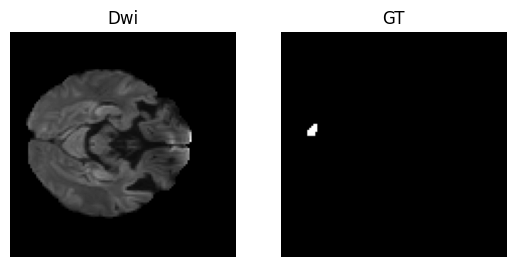

In [34]:
fig, (ax1, ax2) = plt.subplots(1, 2)

slice2show=14
ax1.imshow(dwi_image[:,:,slice2show], cmap='gray')
ax1.set_title('Dwi')
ax1.set_axis_off()


# Show DWI image w/overlayed mask.
ax2.imshow(mask_image[:,:,slice2show], cmap='gray')
#ax2.imshow(mask_image[:,:,slice2show], alpha=0.5, cmap='copper')
ax2.set_title('GT')
ax2.set_axis_off()

In [35]:
dwi_slices = dwi_image.shape[2]
z = np.zeros((dwi_slices, IMG_SIZE,IMG_SIZE))

for j in range(dwi_slices):
    z[j,:,:] =Crop_or_pad_image(dwi_image[:,:,j+0],(IMG_SIZE,IMG_SIZE),coord_dict);
z.shape

(73, 128, 128)

In [36]:
msk_slices = mask_image.shape[2]
y = np.zeros((msk_slices, IMG_SIZE,IMG_SIZE))

for j in range(msk_slices):
    y[j,:,:] =Crop_or_pad_image(mask_image[:,:,j+0], (IMG_SIZE, IMG_SIZE),coord_dict);
y.shape

(73, 128, 128)

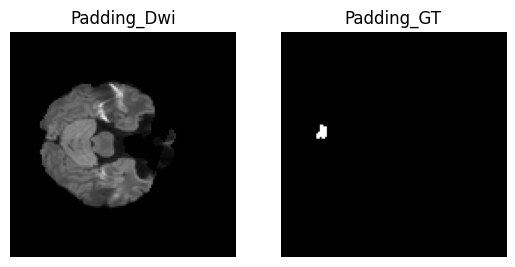

In [44]:
fig, (ax1, ax2) = plt.subplots(1, 2)

slice2show=10
ax1.imshow(z[slice2show,:,:], cmap='gray')
ax1.set_title('Padding_Dwi')
ax1.set_axis_off()


# Show DWI image w/overlayed mask.
ax2.imshow(y[slice2show,:,:], cmap='gray')
#ax2.imshow(mask_image[:,:,slice2show], alpha=0.5, cmap='copper')
ax2.set_title('Padding_GT')
ax2.set_axis_off()

(72, 128, 128, 1)
3/3 [==============================] - 0s 176ms/step


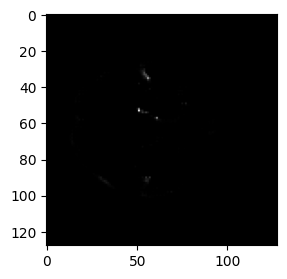

In [45]:
X = np.zeros((72,IMG_SIZE,IMG_SIZE,1))
for j in range(72):
    X[j,:,:,0] =Crop_or_pad_image(dwi_image[:,:,j+0],(IMG_SIZE,IMG_SIZE),coord_dict);
print(X.shape)

pred_wt=model.predict(X)
fig, ax = plt.subplots(1,1, figsize=(3,3))
ax.imshow(pred_wt[10,:,:,:],cmap='gray')

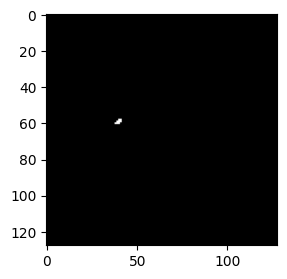

In [30]:
y_pred = np.where(pred_wt >= 0.5, 1.0, 0.0).astype(np.float32)
y_pred_thresholded = y_pred
#dice loss
fig, ax = plt.subplots(1,1, figsize=(3,3))
ax.imshow(y_pred_thresholded[28,:,:,:],cmap='gray')

3/3 [==============================] - 0s 12ms/step
(72, 128, 128, 32)


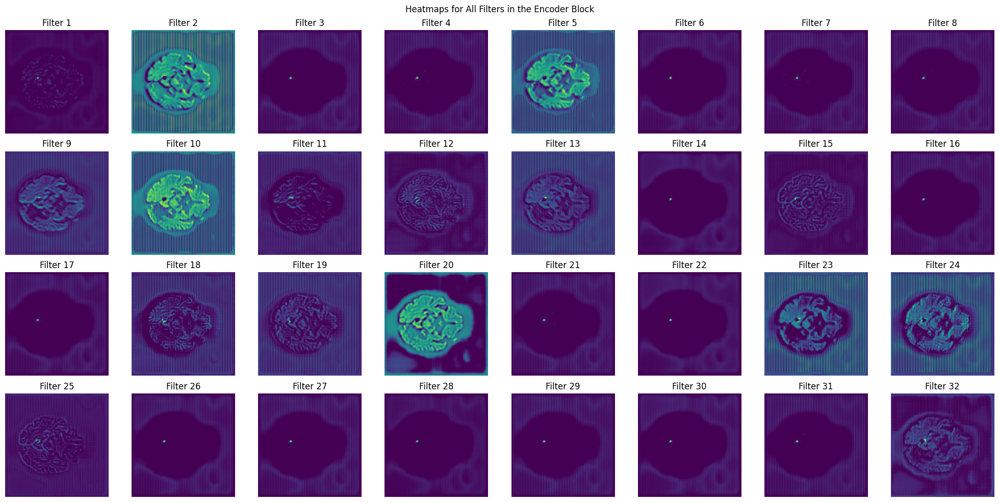

In [31]:
import matplotlib.pyplot as plt
import numpy as np
from tensorflow.keras.models import Model

# Load the trained U-Net model and weights
#model = UNetWithCTAM(input_shape=(128, 128, 1), num_classes=1)
model.load_weights('ISLES22_Unet7M_1dropout_depthwise_output.h5')

# Create a new model that outputs the activations of the first encoder block (enc1)
first_encoder_model = Model(inputs=model.input, outputs=model.get_layer('activation_17').output)#conv2d_17,activation_17

# Load a sample input image (ensure it's resized to 128x128 and normalized)
#sample_image = ...  # Replace with your image loading code
#sample_image = np.expand_dims(sample_image, axis=0)  # Add batch dimension if needed

# Get activations for the first encoder block
activations = first_encoder_model.predict(X)
print(activations.shape)

# Get the number of filters in the activation output
num_filters = activations.shape[-1]

# Plot all filter activations as heatmaps
fig, axes = plt.subplots(nrows=int(np.ceil(num_filters / 8)), ncols=8, figsize=(20, 10))  # Adjust grid size for visualization
axes = axes.flatten()

for i in range(num_filters):
    heatmap = activations[28, :, :, i]  # Get the i-th filter
    heatmap = (heatmap - np.min(heatmap)) / (np.max(heatmap) - np.min(heatmap) + 1e-8)  # Normalize for better visualization

    axes[i].imshow(heatmap, cmap='viridis')
    axes[i].axis('off')
    axes[i].set_title(f"Filter {i+1}")

# Turn off extra subplots if the number of filters is not a multiple of 8
for j in range(num_filters, len(axes)):
    axes[j].axis('off')

plt.suptitle("Heatmaps for All Filters in the Encoder Block")
plt.tight_layout()
plt.show()




In [28]:
def dice_coeff(y_true,y_pred):
    # Ensure both tensors are of type float32
    y_true = tf.cast(y_true, tf.float32)
    y_pred = tf.cast(y_pred, tf.float32)
    
    y_true_new = K.flatten(y_true)
    y_pred_new = K.flatten(y_pred)
    denominator = K.sum(y_true_new) + K.sum(y_pred_new)
    if denominator == 0.0:
        return 1.0
    numerator = K.sum(y_true_new * y_pred_new)
    dice = (2.0*numerator)/(denominator)
    #dice = round(dice, 3)
    return dice

def iou(y_true,y_pred):
    # Ensure both tensors are of type float32
    y_true = tf.cast(y_true, tf.float32)
    y_pred = tf.cast(y_pred, tf.float32)
    
    y_true = K.flatten(y_true)
    y_pred = K.flatten(y_pred)
    intersec = K.sum(y_true * y_pred)
    union = K.sum(y_true + y_pred)
    if union == 0.0:
        return 1.0
    iou = (intersec) / (union- intersec)
    #iou = round(iou, 3)
    return iou

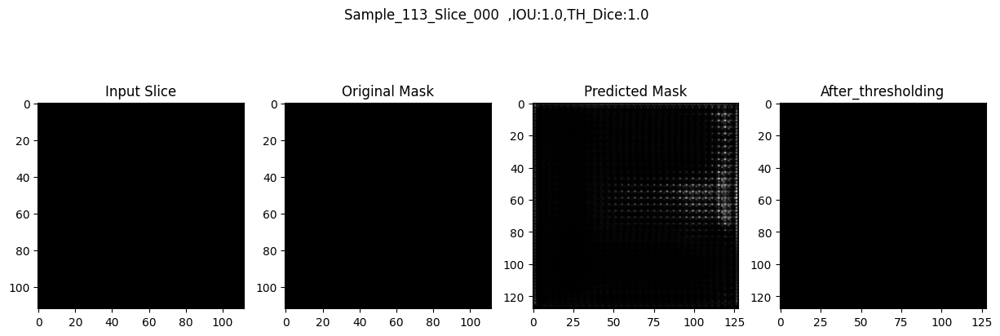

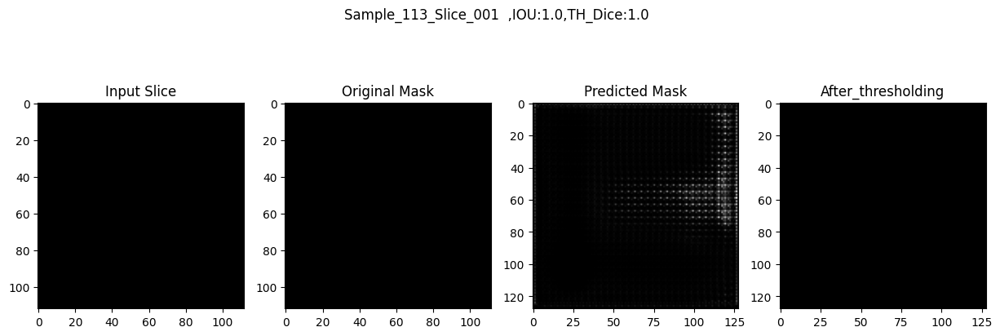

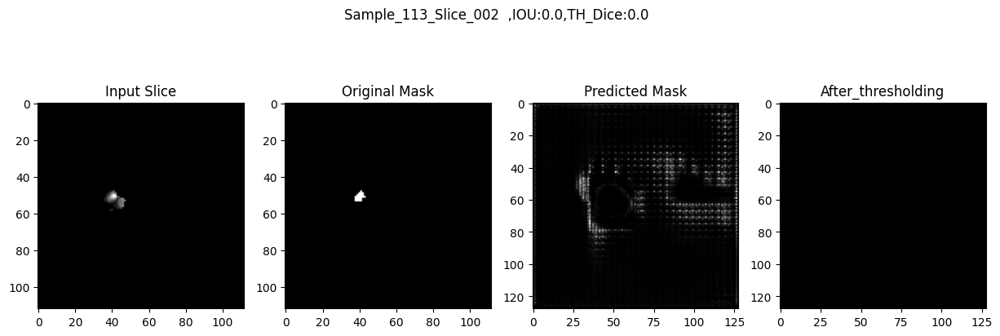

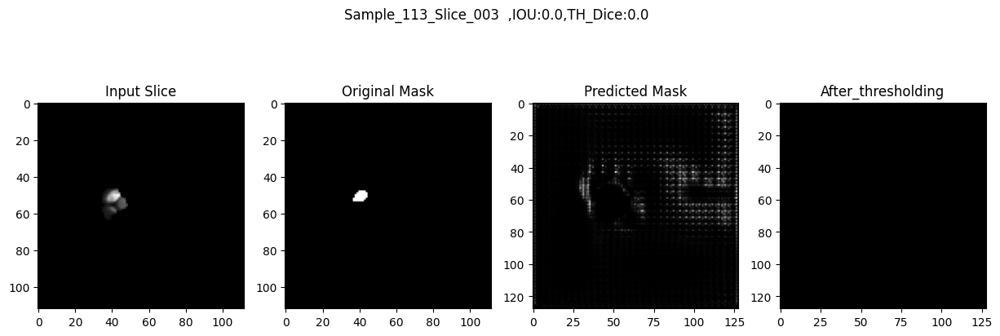

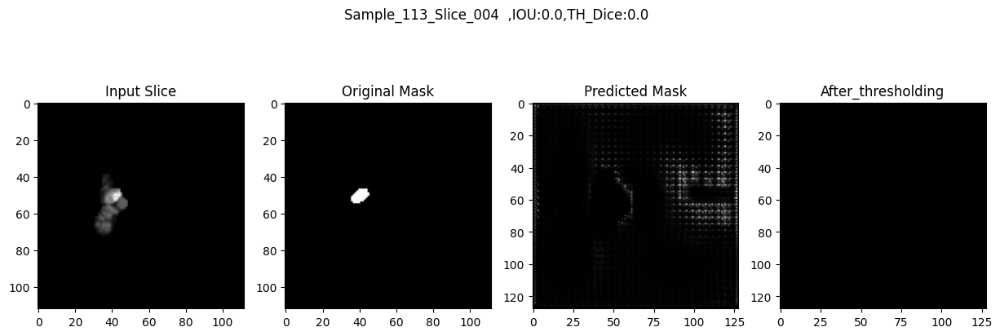

...

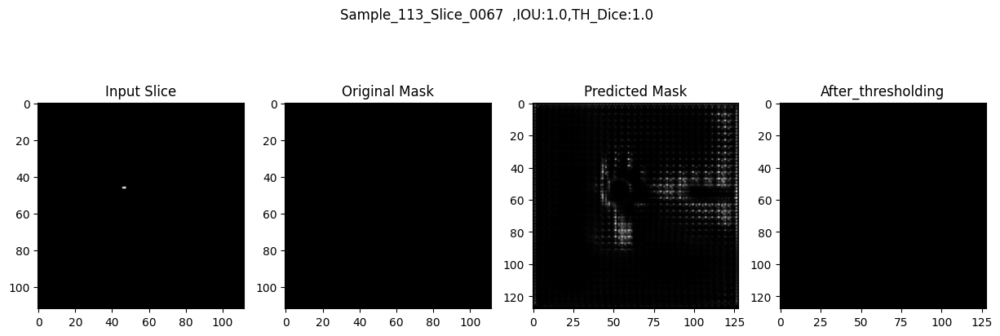

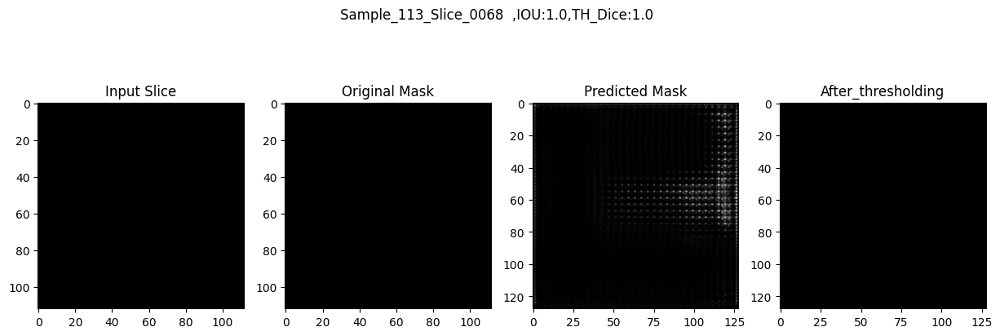

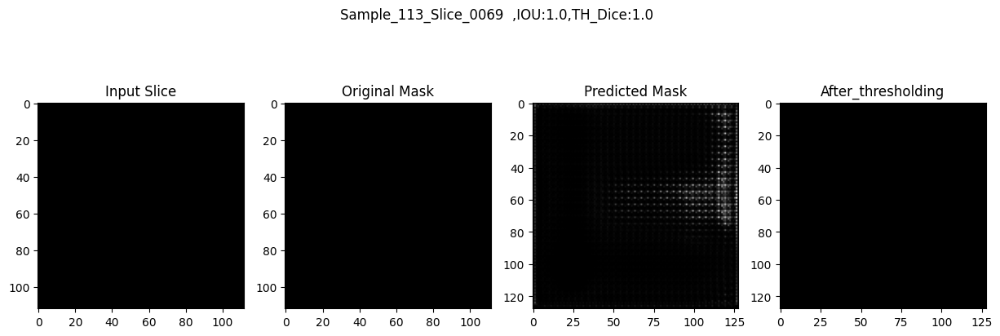

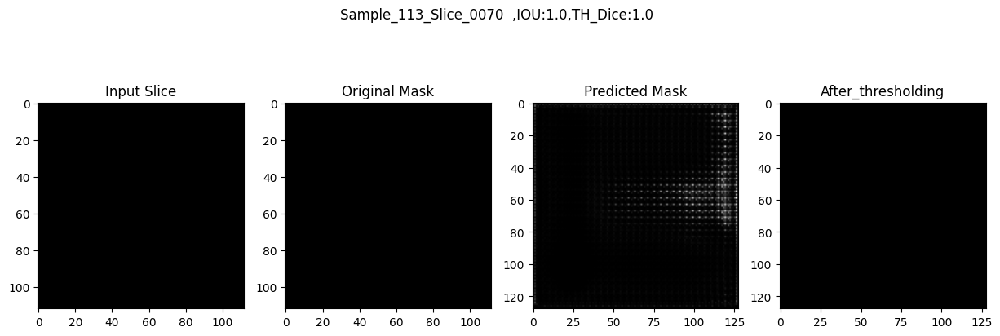

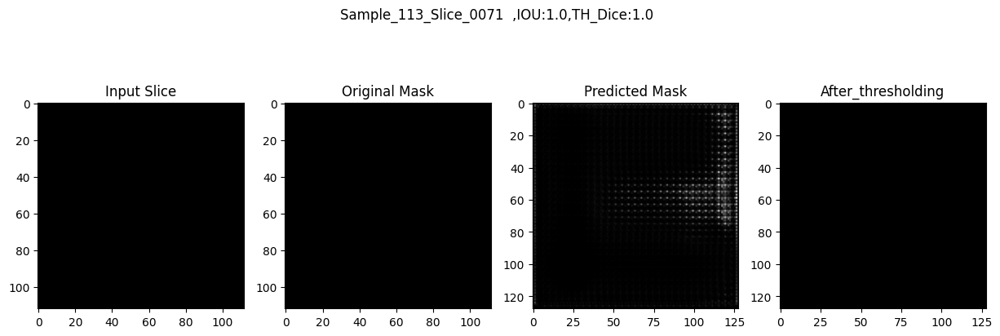

th_average_dice 0.7799133230000734
th_average_iou 0.7248723890839351
Number of slices with zero Dice score: 7
Number of slices with one Dice score: 31
Number of slices with gt60 Dice score: 29
Number of slices with ln60 Dice score: 5


In [55]:
# Specify the directory to save the plot images
output_directory = "E:\\Compare_Attention_ISLES22_result\\Unet31M\\AllSample"
os.makedirs(output_directory, exist_ok=True)

zero_dice_count = 0
one_dice_count = 0
gt60_dice_count = 0
ln60_dice_count = 0

dice_values = []
th_dice_values = []
Iou_values = []
# Plot each slice along with the original mask and predicted mask
for i in range(0,72):
    plt.figure(figsize=(15, 5))

    # Plot the original image
    plt.subplot(1, 4, 1)
    plt.imshow(dwi_image[:,:,i], cmap='gray')
    plt.title('Input Slice')

    # Plot the original mask
    plt.subplot(1, 4, 2)
    plt.imshow(mask_image[:,:,i], cmap='gray')
    plt.title('Original Mask')

    # Plot the predicted mask
    plt.subplot(1, 4, 3)
    plt.imshow(pred_wt[i,:,:,0], cmap='gray')
    plt.title('Predicted Mask')
    
    # Plot the predicted mask
    plt.subplot(1, 4, 4)
    plt.imshow(y_pred_thresholded[i,:,:,0], cmap='gray')
    plt.title('After_thresholding')

    #plt.suptitle(f"Slice: {i+1}")
    #Pred_dice = dice_coeff(mask_image[:,:,i], pred_wt[i,:,:,0])
    #dice = dice_coeff(mask_image[:,:,i], y_pred_thresholded[i,:,:,0])
    #Iou = iou(mask_image[:,:,i], y_pred_thresholded[i,:,:,0])
    dice = dice_coeff(y[i,:,:], y_pred_thresholded[i,:,:,0])
    Iou = iou(y[i,:,:], y_pred_thresholded[i,:,:,0])
    
    #dice_values.append(Pred_dice)
    th_dice_values.append(dice)
    Iou_values.append(Iou)
    
    # Check if Dice score is zero
    if dice == 0:
        zero_dice_count += 1
    elif dice == 1:
        one_dice_count += 1
    elif dice >= 0.6:
        gt60_dice_count += 1
    elif dice < 0.6:
        ln60_dice_count += 1
        
    plt.suptitle(f"Sample_113_Slice_00{i}  ,IOU:{Iou},TH_Dice:{dice}")
    #print(f'Dice Score: {dice}')
    #plt.savefig(f'plot_{i}.png')
    #plt.show()
        
    # Save the plot image in the output folder
    output_filename = f'Sample_113_Slice_00{i}.png'
    output_path = os.path.join(output_directory, output_filename)
    plt.savefig(output_path)
    plt.show()
    plt.close()  # Close the figure to release memory
 


 #Print the count of zero Dice scores
#average_dice = np.mean(dice_values)
#print('average_dice',average_dice)
th_average_dice = np.mean(th_dice_values)
print('th_average_dice',th_average_dice)
average_Iou = np.mean(Iou_values)
print('th_average_iou',average_Iou)

# Print the count of zero Dice scores
print(f"Number of slices with zero Dice score: {zero_dice_count}") 
print(f"Number of slices with one Dice score: {one_dice_count}") 
print(f"Number of slices with gt60 Dice score: {gt60_dice_count}") 
print(f"Number of slices with ln60 Dice score: {ln60_dice_count}")  


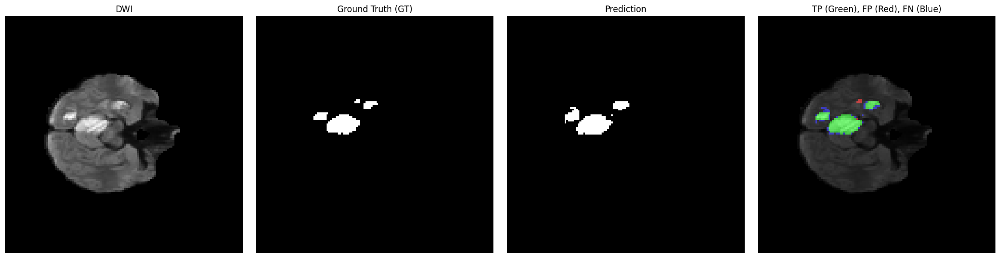

In [30]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

# Specify the directory to save the plot images
output_directory = "E:\\Compare_Attention_ISLES22_result\\Unet"
os.makedirs(output_directory, exist_ok=True)

# Assuming dwi_image, mask_image, and pred_image are 3D numpy arrays.
# pred_image is the predicted segmentation.

slice2show = 26

# Compute true positive, false positive, and false negative regions
true_positive = np.logical_and(y[slice2show,:,:], y_pred_thresholded[slice2show,:,:,0])
false_positive = np.logical_and(np.logical_not(y[slice2show,:,:]), y_pred_thresholded[slice2show,:,:,0])
false_negative = np.logical_and(y[slice2show,:,:], np.logical_not(y_pred_thresholded[slice2show,:,:,0]))

fig, (ax1, ax2, ax3, ax4) = plt.subplots(1, 4, figsize=(20, 5))

# Show DWI image.
ax1.imshow(z[slice2show,:,:], cmap='gray')
ax1.set_title('DWI')
ax1.set_axis_off()

# Show ground truth mask.
ax2.imshow(y[slice2show,:,:], cmap='gray')
ax2.set_title('Ground Truth (GT)')
ax2.set_axis_off()

# Show predicted mask.
ax3.imshow(y_pred_thresholded[slice2show,:,:,0], cmap='gray')
ax3.set_title('Prediction')
ax3.set_axis_off()

# Create color overlays for true positive, false positive, and false negative regions
overlay = np.zeros((z.shape[1], z.shape[2], 3), dtype=np.float32)

# Set the colors (R, G, B) for each region
overlay[..., 1] = true_positive  # Green channel for true positives
overlay[..., 2] = false_positive  # Blue channel for false positives
overlay[..., 0] = false_negative  # Red channel for false negatives


# Show the DWI image with the overlay
ax4.imshow(z[slice2show,:,:], cmap='gray', alpha=1)
ax4.imshow(overlay, alpha=0.5)  # Overlay with transparency

ax4.set_title('TP (Green), FP (Red), FN (Blue)')
ax4.set_axis_off()

plt.tight_layout()
#plt.show()

# Save the plot image in the output folder
output_filename = f'Sample_113_Slice_{slice2show}.png'
output_path = os.path.join(output_directory, output_filename)
plt.savefig(output_path)
plt.show()
plt.close()  # Close the figure to release memory
 


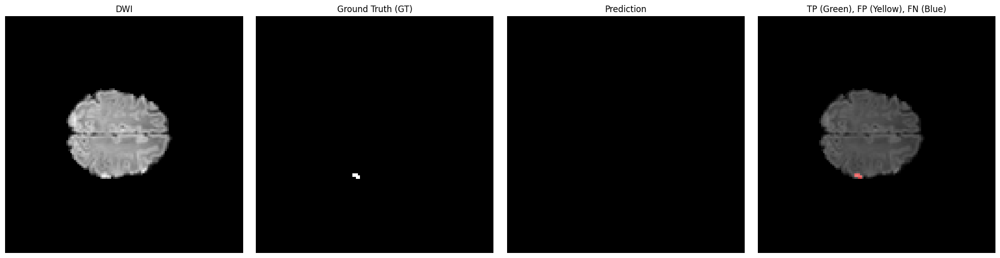

In [65]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import os

# Specify the directory to save the plot images
output_directory = "E:\\FEUNet_Attention_ISLES22_result\\Unet_7M\\Sample"
os.makedirs(output_directory, exist_ok=True)

# Assuming dwi_image, mask_image, and pred_image are 3D numpy arrays.
# pred_image is the predicted segmentation.

slice2show = 56

# Compute true positive, false positive, and false negative regions
true_positive = np.logical_and(y[slice2show,:,:], y_pred_thresholded[slice2show,:,:,0])
false_positive = np.logical_and(np.logical_not(y[slice2show,:,:]), y_pred_thresholded[slice2show,:,:,0])
false_negative = np.logical_and(y[slice2show,:,:], np.logical_not(y_pred_thresholded[slice2show,:,:,0]))

fig, (ax1, ax2, ax3, ax4) = plt.subplots(1, 4, figsize=(20, 5))

# Show DWI image.
ax1.imshow(z[slice2show,:,:], cmap='gray')
ax1.set_title('DWI')
ax1.set_axis_off()

# Show ground truth mask.
ax2.imshow(y[slice2show,:,:], cmap='gray')
ax2.set_title('Ground Truth (GT)')
ax2.set_axis_off()

# Show predicted mask.
ax3.imshow(y_pred_thresholded[slice2show,:,:,0], cmap='gray')
ax3.set_title('Prediction')
ax3.set_axis_off()

# Create color overlays for true positive, false positive, and false negative regions
overlay = np.zeros((z.shape[1], z.shape[2], 3), dtype=np.float32)

# Set the colors (R, G, B) for each region
overlay[..., 1] = true_positive          # Green channel for true positives
overlay[..., 2] = false_positive         # blue channel for false positives (Yellow = Red + Green)
overlay[..., 1] += false_positive        # Green channel for false positives (Yellow = Red + Green)
overlay[..., 0] = false_negative         # red channel for false negatives

# Show the DWI image with the overlay
ax4.imshow(z[slice2show,:,:], cmap='gray', alpha=1)
ax4.imshow(overlay, alpha=0.5)  # Overlay with transparency

ax4.set_title('TP (Green), FP (Yellow), FN (Blue)')
ax4.set_axis_off()

plt.tight_layout()

# Save the plot image in the output folder
output_filename = f'Sample_223_Slice_{slice2show}.png'
output_path = os.path.join(output_directory, output_filename)
plt.savefig(output_path)
plt.show()
plt.close()  # Close the figure to release memory


In [64]:
import os
import numpy as np
import matplotlib.pyplot as plt

# Specify the directory to save the plot images
output_directory = "E:\\FEUNet_Attention_ISLES22_result\\FEUnet_Under_over_segment result\\Unet31M\\newSlices"
os.makedirs(output_directory, exist_ok=True)

# Assuming dwi_image, mask_image, and pred_image are 3D numpy arrays.
# pred_image is the predicted segmentation.

sample = 113
slice2show = 26
dpi = 600  # Set the desired DPI for saving the figures

# Compute true positive, false positive, and false negative regions
true_positive = np.logical_and(y[slice2show,:,:], y_pred_thresholded[slice2show,:,:,0])
false_positive = np.logical_and(np.logical_not(y[slice2show,:,:]), y_pred_thresholded[slice2show,:,:,0])
false_negative = np.logical_and(y[slice2show,:,:], np.logical_not(y_pred_thresholded[slice2show,:,:,0]))

# Plot DWI image
fig, ax = plt.subplots()
ax.imshow(z[slice2show,:,:], cmap='gray')
#ax.set_title('DWI')
ax.set_axis_off()
output_filename = f'Sample_{sample}_dwi_{slice2show}.png'
output_path = os.path.join(output_directory, output_filename)
plt.savefig(output_path, dpi=dpi, bbox_inches='tight',pad_inches=0)
plt.close()

# Plot Ground Truth mask overlayed on DWI image
fig, ax = plt.subplots()
ax.imshow(z[slice2show,:,:], cmap='gray')
ax.imshow(y[slice2show,:,:], alpha=0.5, cmap='gray')
#ax.set_title('Ground Truth (GT)')
ax.set_axis_off()
output_filename = f'Sample_{sample}_GT_{slice2show}.png'
output_path = os.path.join(output_directory, output_filename)
plt.savefig(output_path, dpi=dpi, bbox_inches='tight',pad_inches=0)
plt.close()

# Plot predicted mask
fig, ax = plt.subplots()
ax.imshow(y_pred_thresholded[slice2show,:,:,0], cmap='gray')
#ax.set_title('Prediction')
ax.set_axis_off()
output_filename = f'Sample_{sample}_Predict_{slice2show}.png'
output_path = os.path.join(output_directory, output_filename)
plt.savefig(output_path, dpi=dpi, bbox_inches='tight',pad_inches=0)
plt.close()

# Create color overlays for true positive, false positive, and false negative regions
overlay = np.zeros((z.shape[1], z.shape[2], 3), dtype=np.float32)

# Set the colors (R, G, B) for each region
overlay[..., 1] = true_positive  # Green channel for true positives
overlay[..., 2] = false_positive  # Blue channel for false positives
overlay[..., 0] = false_negative  # Red channel for false negatives

# Plot DWI image with overlay
fig, ax = plt.subplots()
ax.imshow(z[slice2show,:,:], cmap='gray', alpha=1)
ax.imshow(overlay, alpha=0.5)  # Overlay with transparency
#ax.set_title('TP (Green), FP (Blue), FN (Red)')
ax.set_axis_off()
output_filename = f'Sample_{sample}_Overlay_{slice2show}.png'
output_path = os.path.join(output_directory, output_filename)
plt.savefig(output_path, dpi=dpi, bbox_inches='tight',pad_inches=0)
plt.close()


In [65]:
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# Specify the directory to save the plot images
output_directory = "E:\\FEUNet_Attention_ISLES22_result\\FEUnet_Under_over_segment result\\Unet31M\\newROISlices"
os.makedirs(output_directory, exist_ok=True)

# Assuming dwi_image, mask_image, and pred_image are 3D numpy arrays.
# pred_image is the predicted segmentation.

sample = 113
slice2show = 26
dpi = 600  # Set the desired DPI for saving the figures
output_size = (128, 128)  # Desired output size

# Define the region of interest (ROI) for cropping (x_start, y_start, x_end, y_end)
roi = (20, 35, 80, 75) #(50, 25, 75, 40)s22 #(45, 22, 70, 50)s29

# Compute true positive, false positive, and false negative regions
true_positive = np.logical_and(y[slice2show,:,:], y_pred_thresholded[slice2show,:,:,0])
false_positive = np.logical_and(np.logical_not(y[slice2show,:,:]), y_pred_thresholded[slice2show,:,:,0])
false_negative = np.logical_and(y[slice2show,:,:], np.logical_not(y_pred_thresholded[slice2show,:,:,0]))

# Function to crop, save, and resize images
def save_and_resize_image(data, title, filename, cmap='gray'):
    fig, ax = plt.subplots()
    ax.imshow(data, cmap=cmap)
    #ax.set_title(title)
    ax.set_axis_off()
    # Crop the image
    ax.set_xlim(roi[0], roi[2])
    ax.set_ylim(roi[3], roi[1])
    # Save the cropped image
    cropped_path = os.path.join(output_directory, filename)
    plt.savefig(cropped_path, dpi=dpi, bbox_inches='tight', pad_inches=0)
    plt.close()
    
    # Open the cropped image, resize it, and save again
    with Image.open(cropped_path) as img:
        resized_img = img.resize(output_size, Image.Resampling.LANCZOS)
        resized_img.save(cropped_path)

# Plot and save cropped DWI image
save_and_resize_image(z[slice2show,:,:], 'DWI', f'Sample_{sample}_dwi_{slice2show}.png')

# Plot and save cropped Ground Truth mask overlayed on DWI image
fig, ax = plt.subplots()
ax.imshow(z[slice2show,:,:], cmap='gray')
ax.imshow(y[slice2show,:,:], alpha=0.5, cmap='gray')
#ax.set_title('Ground Truth (GT)')
ax.set_axis_off()
ax.set_xlim(roi[0], roi[2])
ax.set_ylim(roi[3], roi[1])
output_path = os.path.join(output_directory, f'Sample_{sample}_GT_{slice2show}.png')
plt.savefig(output_path, dpi=dpi, bbox_inches='tight', pad_inches=0)
plt.close()
# Resize the saved image
with Image.open(output_path) as img:
    resized_img = img.resize(output_size, Image.Resampling.LANCZOS)
    resized_img.save(output_path)

# Plot and save cropped predicted mask
save_and_resize_image(y_pred_thresholded[slice2show,:,:,0], 'Prediction', f'Sample_{sample}_Predict_{slice2show}.png')

# Create color overlays for true positive, false positive, and false negative regions
overlay = np.zeros((z.shape[1], z.shape[2], 3), dtype=np.float32)

# Set the colors (R, G, B) for each region
overlay[..., 1] = true_positive  # Green channel for true positives
overlay[..., 2] = false_positive  # Blue channel for false positives
overlay[..., 0] = false_negative  # Red channel for false negatives

# Plot and save cropped DWI image with overlay
fig, ax = plt.subplots()
ax.imshow(z[slice2show,:,:], cmap='gray', alpha=1)
ax.imshow(overlay, alpha=0.5)  # Overlay with transparency
#ax.set_title('TP (Green), FP (Blue), FN (Red)')
ax.set_axis_off()
ax.set_xlim(roi[0], roi[2])
ax.set_ylim(roi[3], roi[1])
output_path = os.path.join(output_directory, f'Sample_{sample}_Overlay_{slice2show}.png')
plt.savefig(output_path, dpi=dpi, bbox_inches='tight', pad_inches=0)
plt.close()
# Resize the saved image
with Image.open(output_path) as img:
    resized_img = img.resize(output_size, Image.Resampling.LANCZOS)
    resized_img.save(output_path)


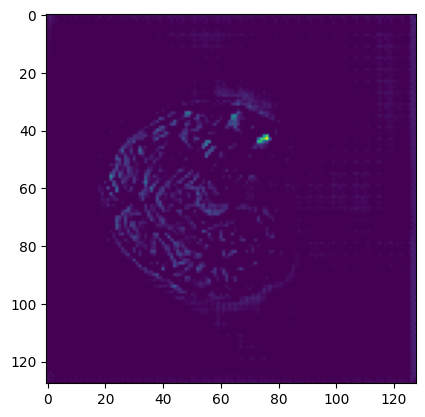

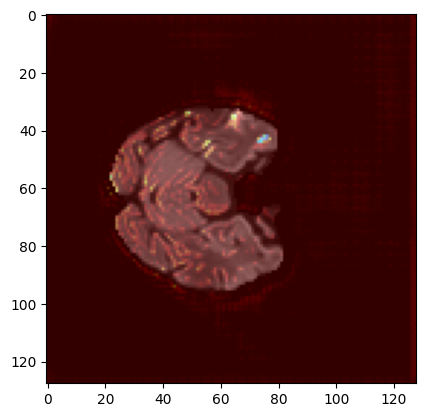

In [30]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import cv2
import nibabel as nib
import os

# Specify the directory to save the plot images
output_directory = "E:\\ISLES_Visual_Results\\FEUNet_Attention_ISLES22_result\\Attention_Map\\UNET"
os.makedirs(output_directory, exist_ok=True)

# Preprocess the NIfTI image with Z-normalization
def preprocess_nii_image(nii_path, target_size):
    img = nib.load(nii_path).get_fdata()
    img = scaler.fit_transform(img.reshape(-1, img.shape[-1])).reshape(img.shape)
    img = Crop_or_pad_image(img[:,:,21], (IMG_SIZE, IMG_SIZE), coord_dict)
    img = img.astype(np.float32)
    img = np.expand_dims(img, axis=0)   # Add batch dimension
    img = np.transpose(img, (0, 1, 2))
    img = np.expand_dims(img, axis=-1)  # Add channel dimension
    return img

# Grad-CAM function for U-Net model
def get_grad_cam(model, img_array, layer_name, class_index):
    grad_model = tf.keras.models.Model(
        inputs=[model.inputs],
        outputs=[model.get_layer(layer_name).output, model.output]
    )

    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(img_array)
        if class_index >= predictions.shape[-1]:
            raise ValueError(f"class_index {class_index} is out of bounds for the predictions with shape {predictions.shape}")
        loss = predictions[:, :, :, class_index]

    output = conv_outputs[0]
    grads = tape.gradient(loss, conv_outputs)[0]
    weights = tf.reduce_mean(grads, axis=(0, 1))

    cam = np.zeros(output.shape[0:2], dtype=np.float32)
    for i, w in enumerate(weights):
        cam += w * output[:, :, i]

    cam = np.maximum(cam, 0)
    cam = cam / np.max(cam)
    cam = np.uint8(255 * cam)
    cam = cv2.resize(cam, (img_array.shape[2], img_array.shape[1]))
    return cam

# Overlay heatmap on the image
def overlay_heatmap(img_array, heatmap, alpha=0.4, colormap=cv2.COLORMAP_JET):
    img = np.squeeze(img_array, axis=0)  # Remove batch dimension
    img = np.squeeze(img, axis=-1)  # Remove channel dimension
    img = cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)  # Convert to BGR
    
    img = np.uint8(255 * (img - np.min(img)) / (np.max(img) - np.min(img)))
    
    heatmap = cv2.applyColorMap(heatmap, colormap)
    output = cv2.addWeighted(heatmap, alpha, img, 1 - alpha, 0)
    return output

# Example usage
nii_path = dwi_path
target_size = (128, 128)  # Adjust according to your model input size
img_array = preprocess_nii_image(nii_path, target_size)

layer_name = 'conv2d_17'
class_index = 0  # Example class index, adjust according to your segmentation task

heatmap = get_grad_cam(model, img_array, layer_name, class_index)

# Save the heatmap
heatmap_filename = 'Sample_39_Slice_0021_heatmap.png'
heatmap_path = os.path.join(output_directory, heatmap_filename)
cv2.imwrite(heatmap_path, heatmap)

# Overlay heatmap on image and save
output = overlay_heatmap(img_array, heatmap)
overlay_filename = 'Sample_39_Slice_0021_overlay.png'
overlay_path = os.path.join(output_directory, overlay_filename)
plt.imsave(overlay_path, output)

# Display heatmap and overlay
plt.imshow(heatmap, cmap='viridis')
plt.show()

plt.imshow(output)
plt.show()


Shape of predictions: (1, 128, 128, 1)


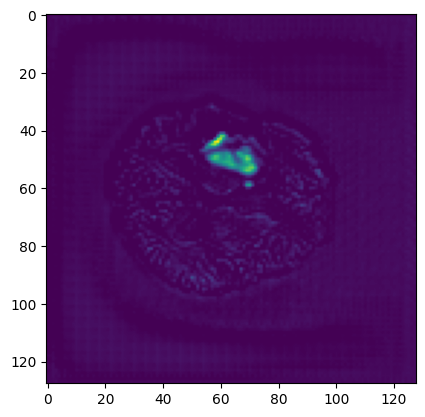

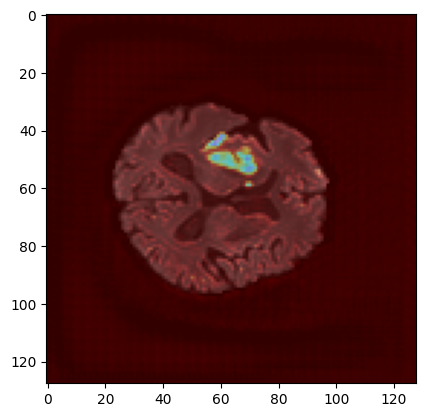

In [35]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import cv2
import nibabel as nib

# Load the U-Net model
# Replace 'unet_model' with your actual U-Net model variable
# For example: unet_model = your_unet_model()

# Preprocess the NIfTI image with Z-normalization
def preprocess_nii_image(nii_path, target_size):
    img = nib.load(nii_path).get_fdata()
    #print('nii',img.shape)
    img=scaler.fit_transform(img.reshape(-1, img.shape[-1])).reshape(img.shape)
    
    
    #img = np.rot90(np.array(img))  # Adjust rotation if needed
    img = Crop_or_pad_image(img[:,:,35],(IMG_SIZE,IMG_SIZE),coord_dict);
    #img = cv2.resize(img[:,:], target_size)
    #img = img[:,:,25]
    #dwi_image=cv2.resize(dwi_image[:,:],(112,112))
    
    # Z-normalization
    #dwi_image=scaler.fit_transform(dwi_image.reshape(-1, dwi_image.shape[-1])).reshape(dwi_image.shape)
    #mean = np.mean(img)
    #std = np.std(img)
    #img = (img - mean) / std
    
    img = img.astype(np.float32)
    #print('img',img.shape)
    
    img = np.expand_dims(img, axis=0)   # Add batch dimension
    img = np.transpose(img, (0, 1, 2))
    img = np.expand_dims(img, axis=-1)  # Add channel dimension
    #print(img.shape)
    return img

# Grad-CAM function for U-Net model
def get_grad_cam(model, img_array, layer_name, class_index):
    grad_model = tf.keras.models.Model(
        inputs=[model.inputs],
        outputs=[model.get_layer(layer_name).output, model.output]
    )

    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(img_array)
        # Inspect the shape of predictions
        print("Shape of predictions:", predictions.shape)
        if class_index >= predictions.shape[-1]:
            raise ValueError(f"class_index {class_index} is out of bounds for the predictions with shape {predictions.shape}")
        loss = predictions[:, :, :, class_index]

    output = conv_outputs[0]
    grads = tape.gradient(loss, conv_outputs)[0]
    weights = tf.reduce_mean(grads, axis=(0, 1))

    cam = np.zeros(output.shape[0:2], dtype=np.float32)
    for i, w in enumerate(weights):
        cam += w * output[:, :, i]

    cam = np.maximum(cam, 0)
    cam = cam / np.max(cam)
    cam = np.uint8(255 * cam)
    cam = cv2.resize(cam, (img_array.shape[2], img_array.shape[1]))
    return cam

# Overlay heatmap on the image
def overlay_heatmap(img_array, heatmap, alpha=0.4, colormap=cv2.COLORMAP_JET):
    img = np.squeeze(img_array, axis=0)  # Remove batch dimension
    img = np.squeeze(img, axis=-1)  # Remove channel dimension
    img = cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)  # Convert to BGR
    
    # Ensure img is uint8
    img = np.uint8(255 * (img - np.min(img)) / (np.max(img) - np.min(img)))
    
    heatmap = cv2.applyColorMap(heatmap, colormap)
    output = cv2.addWeighted(heatmap, alpha, img, 1 - alpha, 0)
    return output

# Example usage
nii_path = dwi_path
target_size = (128,128)  # Adjust according to your model input size
img_array = preprocess_nii_image(nii_path, target_size)

# Assuming the last layer name of the encoder is 'last_conv_layer_name'
# and your segmentation model predicts a multi-channel output with class index
layer_name = 'conv2d_17'
class_index = 0  # Example class index, adjust according to your segmentation task

heatmap = get_grad_cam(model, img_array, layer_name, class_index)

# Display heatmap
plt.imshow(heatmap, cmap='viridis')
plt.show()

# Overlay heatmap on image and display
output = overlay_heatmap(img_array, heatmap)
plt.imshow(output)
plt.show()


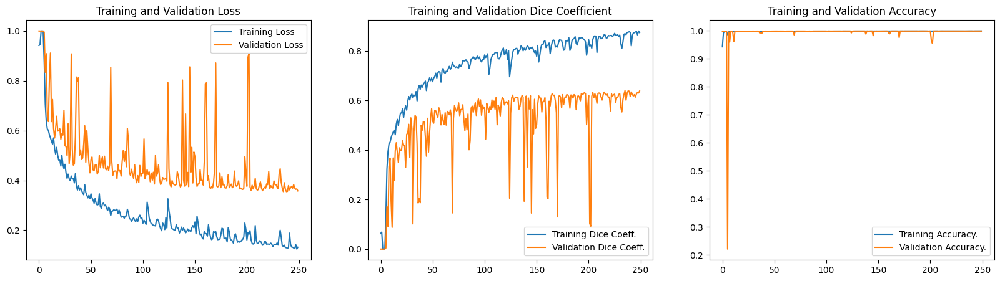

In [27]:
loss = history.history['loss']
val_loss = history.history['val_loss']

dice = history.history['dice_coeff']
val_dice = history.history['val_dice_coeff']

acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

epochs_range = range(250)

plt.figure(figsize=(20, 5))
plt.subplot(1, 3, 1)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend(loc='best')
plt.title('Training and Validation Loss')

plt.subplot(1, 3, 2)
plt.plot(epochs_range, dice, label='Training Dice Coeff.')
plt.plot(epochs_range, val_dice, label='Validation Dice Coeff.')
plt.legend(loc='best')
plt.title('Training and Validation Dice Coefficient')

plt.subplot(1, 3, 3)
plt.plot(epochs_range, acc, label='Training Accuracy.')
plt.plot(epochs_range, val_acc, label='Validation Accuracy.')
plt.legend(loc='best')
plt.title('Training and Validation Accuracy')

plt.show()

In [22]:
import tensorflow as tf
from keras.models import load_model
import keras.backend as K
from tensorflow.python.framework.convert_to_constants import convert_variables_to_constants_v2_as_graph

# # Define your custom loss function
# def dice_coeff_loss(y_true, y_pred):
#     intersection = K.sum(y_true * y_pred)
#     union = K.sum(y_true) + K.sum(y_pred)
#     dice = (2. * intersection + K.epsilon()) / (union + K.epsilon())
#     return 1 - dice

# # Define your custom metric function
# def dice_coeff(y_true, y_pred):
#     intersection = K.sum(y_true * y_pred)
#     union = K.sum(y_true) + K.sum(y_pred)
#     dice = (2. * intersection + K.epsilon()) / (union + K.epsilon())
#     return dice

# # Define your custom iou function (if needed)
# def iou(y_true, y_pred):
#     intersection = K.sum(K.abs(y_true * y_pred), axis=[1, 2, 3])
#     sum_ = K.sum(K.abs(y_true) + K.abs(y_pred), axis=[1, 2, 3])
#     iou = (intersection + K.epsilon()) / (sum_ - intersection + K.epsilon())
#     return iou
def dice_coeff(y_true,y_pred):
    # Perform the conditional operation using TensorFlow
    # Set values less than 2.2 to 0
    y_pred = tf.where(y_pred < 0.2, tf.zeros_like(y_pred), y_pred)
    y_true_new = K.flatten(y_true)
    y_pred_new = K.flatten(y_pred)
    denominator = K.sum(y_true_new) + K.sum(y_pred_new)
    if denominator == 0.0:
        return 1.0
    numerator = K.sum(y_true_new * y_pred_new)
    return (2.0*numerator)/(denominator)

def dice_coeff_loss(y_true,y_pred):
    return 1.0- dice_coeff(y_true,y_pred)

def iou(y_true,y_pred):
    y_pred = tf.where(y_pred < 0.2, tf.zeros_like(y_pred), y_pred)
    intersec = K.sum(y_true * y_pred)
    union = K.sum(y_true + y_pred)
    if union == 0.0:
        return 1.0
    iou = (intersec) / (union- intersec)
    return iou

def precision_score_(y_true, y_pred):
    #y_pred = tf.where(y_pred < 0.2, tf.zeros_like(y_pred), y_pred)
    y_true_new = K.flatten(y_true)
    y_pred_new = K.flatten(y_pred)
    intersect = K.sum(y_pred_new*y_true_new)
    total_pixel_pred = K.sum(y_pred_new)
    #precision = intersect/total_pixel_pred
    return intersect/total_pixel_pred

# Load the model with the custom loss function and custom metric
model = load_model("ISLES22_Unet7M.h5", 
                   custom_objects={'dice_coeff_loss': dice_coeff_loss, 'dice_coeff': dice_coeff, 'iou': iou, 'precision_score_':precision_score_})

def get_flops(model):
    # Create a concrete function from the Keras model
    concrete = tf.function(lambda inputs: model(inputs))
    concrete_func = concrete.get_concrete_function(
        [tf.TensorSpec([1] + input.shape[1:], input.dtype) for input in model.inputs])
    
    # Convert variables to constants and get the frozen graph
    frozen_func, _ = convert_variables_to_constants_v2_as_graph(concrete_func)
    
    # Run metadata for profiling
    run_meta = tf.compat.v1.RunMetadata()
    opts = tf.compat.v1.profiler.ProfileOptionBuilder.float_operation()

    # Profile the frozen graph to get the FLOPs
    flops = tf.compat.v1.profiler.profile(graph=frozen_func.graph, run_meta=run_meta, cmd='op', options=opts)

    return flops.total_float_ops

# Calculate and print the FLOPs
flops = get_flops(model)
print(f"FLOPs: {flops}")


Instructions for updating:
Use `tf.compat.v1.graph_util.tensor_shape_from_node_def_name`
FLOPs: 6022709248
